<a href="https://colab.research.google.com/github/vusu4242/hm2_vus_konovalenko/blob/main/notebooks/01_two_stage_faster_rcnn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Two-stage anchor-based detector: Faster R-CNN
Setup


In [ ]:
!nvidia-smi --query-gpu=name,memory.total --format=csv

name, memory.total [MiB]
Tesla T4, 15360 MiB


In [ ]:
import os
from pathlib import Path
from google.colab import userdata
os.environ['KAGGLE_API_TOKEN'] = userdata.get('hm2')

if not Path('/content/data/train').exists():
    !kaggle competitions download -c multiple-object-video-detection-hw-2-ucu-ai-2026 -p /content/data
    !cd /content/data && unzip -q '*.zip' && rm *.zip
else:
    print('Data is here')
ROOT = Path('/content/data')

100% 9.88G/9.88G [01:14<00:00, 143MB/s]



In [ ]:
from google.colab import drive
drive.mount('/content/drive')

PREP = Path('/content/prepared')
if not PREP.exists():
    !unzip -q /content/drive/MyDrive/hw2_prepared.zip -d /content
for split in ['train', 'val']:
    n = sum(1 for _ in (PREP / split / 'images').rglob('*.jpg'))
    print(f'{split}: {n} кадрів')

Mounted at /content/drive
train: 4868 кадрів
val: 571 кадрів


## Dataset
Reads the preprocessed frames and YOLO labels and converts them to the torchvision format: boxes as `[x1, y1, x2, y2]` in pixels, class ids shifted by +1 (0 is reserved for background). Training augmentation: horizontal flip (p=0.5). Normalization (ImageNet mean/std) and resizing are done inside the torchvision model.

In [ ]:
import random, cv2, numpy as np, torch
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms.functional as TF

CLASSES = ['person', 'bicycle', 'car', 'van', 'truck', 'tricycle', 'bus', 'motor']
SEED = 42

def seed_everything(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
seed_everything()

class DetDataset(Dataset):
    def __init__(self, split, train=False):
        self.imgs = sorted((PREP / split / 'images').rglob('*.jpg'))
        self.train = train

    def __len__(self):
        return len(self.imgs)

    def __getitem__(self, i):
        p = self.imgs[i]
        img = cv2.cvtColor(cv2.imread(str(p)), cv2.COLOR_BGR2RGB)
        H, W = img.shape[:2]
        lp = Path(str(p).replace('/images/', '/labels/')).with_suffix('.txt')
        a = np.loadtxt(lp, ndmin=2) if lp.stat().st_size else np.zeros((0, 5))
        cls, cx, cy, w, h = a.T
        boxes = np.stack([(cx - w/2) * W, (cy - h/2) * H, (cx + w/2) * W, (cy + h/2) * H], 1)
        keep = (boxes[:, 2] - boxes[:, 0] > 1) & (boxes[:, 3] - boxes[:, 1] > 1)   # прибираємо вироджені бокси
        boxes, cls = boxes[keep], cls[keep]
        if self.train and random.random() < 0.5:                                    # горизонтальний фліп
            img = img[:, ::-1].copy()
            boxes[:, [0, 2]] = W - boxes[:, [2, 0]]
        target = {'boxes': torch.as_tensor(boxes, dtype=torch.float32).reshape(-1, 4),
                  'labels': torch.as_tensor(cls + 1, dtype=torch.int64)}            # +1: 0 = фон
        return TF.to_tensor(img), target

def collate(batch):
    return tuple(zip(*batch))

g = torch.Generator().manual_seed(SEED)
train_ds = DetDataset('train', train=True)
train_dl = DataLoader(train_ds, batch_size=4, shuffle=True, num_workers=2, collate_fn=collate, generator=g)
print('train frames:', len(train_ds))

train frames: 4868


#### Check: one training batch with boxes

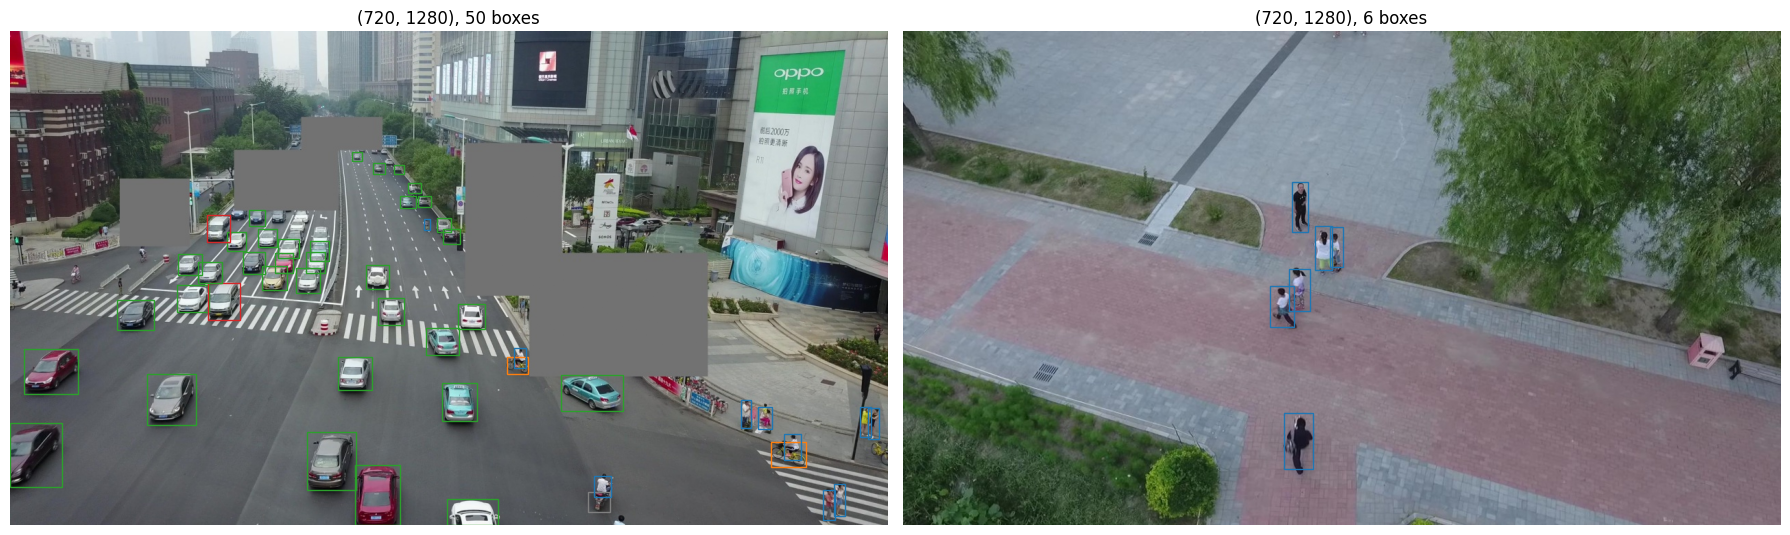

In [ ]:
import matplotlib.pyplot as plt, matplotlib.patches as patches
COLORS = plt.cm.tab10(range(8))

imgs, targets = next(iter(train_dl))
fig, axes = plt.subplots(1, 2, figsize=(18, 6))
for ax, img, t in zip(axes, imgs, targets):
    ax.imshow(img.permute(1, 2, 0))
    for (x1, y1, x2, y2), l in zip(t['boxes'].tolist(), t['labels'].tolist()):
        ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, lw=1, ec=COLORS[l - 1]))
    ax.set_title(f'{tuple(img.shape[1:])}, {len(t["boxes"])} boxes'); ax.set_axis_off()
plt.tight_layout(); plt.show()

на лівому кадрі є видимі люди й машини без боксів. частина об'єктів не розмічена. Модель їх знаходитиме, а метрика рахуватиме як помилки - кандидат для аналізу помилок (крок 8).

## Model and training setup
Faster R-CNN with a ResNet-50-FPN backbone (torchvision `fasterrcnn_resnet50_fpn_v2`), initialised from COCO-pretrained weights; the box predictor is replaced with a new head for 8 classes + background.
Settings changed from the torchvision defaults, based on the EDA:
- `min_size=720, max_size=1280`: frames are already 1280×720, so the model does not rescale them.
- `box_detections_per_img=300`: up to 180 objects per frame (default is only 100).
- `box_score_thresh=0.001`: keep low-confidence detections so mAP is computed correctly.

`build_model(**overrides)` lets each experiment change one parameter while everything else stays the same.

In [ ]:
import time, torchvision
from torchvision.models.detection import fasterrcnn_resnet50_fpn_v2, FasterRCNN_ResNet50_FPN_V2_Weights
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor

DEVICE = 'cuda'
BASE = dict(
    min_size=720, max_size=1280,                                # кадри вже 1280×720
    box_detections_per_img=300,                                 # до 180 об'єктів на кадр (EDA)
    box_score_thresh=0.001,                                     # низький поріг для коректного mAP
    rpn_post_nms_top_n_train=2000, rpn_post_nms_top_n_test=1000,   # к-сть proposals (default)
    box_batch_size_per_image=512, box_positive_fraction=0.25,      # RoI sampling (default)
)

def build_model(**overrides):
    """Faster R-CNN з COCO-вагами; overrides змінюють окремі параметри для експериментів."""
    m = fasterrcnn_resnet50_fpn_v2(weights=FasterRCNN_ResNet50_FPN_V2_Weights.DEFAULT, **{**BASE, **overrides})
    in_f = m.roi_heads.box_predictor.cls_score.in_features
    m.roi_heads.box_predictor = FastRCNNPredictor(in_f, len(CLASSES) + 1)   # 8 класів + фон
    return m.to(DEVICE)

#### Speed and memory check
A few training iterations to verify that the pipeline runs, fits into GPU memory, and to estimate the time per epoch.

In [ ]:
model = build_model()
opt = torch.optim.SGD([p for p in model.parameters() if p.requires_grad], lr=0.001, momentum=0.9, weight_decay=1e-4)
scaler = torch.amp.GradScaler('cuda')
model.train()
it = iter(train_dl)
for i in range(12):
    imgs, tg = next(it)
    imgs = [x.to(DEVICE) for x in imgs]
    tg = [{k: v.to(DEVICE) for k, v in t.items()} for t in tg]
    with torch.autocast('cuda', dtype=torch.float16):          # mixed precision: швидше і менше пам'яті
        losses = model(imgs, tg)
    loss = sum(losses.values())
    opt.zero_grad(); scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
    if i == 1:                                                  # перші 2 ітерації — розігрів
        torch.cuda.synchronize(); t0 = time.time()
torch.cuda.synchronize()
sec_it = (time.time() - t0) / 10

print('losses:', {k: round(v.item(), 3) for k, v in losses.items()})
print(f'{sec_it:.2f} s/iter -> одна епоха ≈ {sec_it * len(train_dl) / 60:.0f} хв')
print(f'пік пам\'яті GPU: {torch.cuda.max_memory_allocated() / 1e9:.1f} GB')
del model, opt; torch.cuda.empty_cache()

Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_v2_coco-dd69338a.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_resnet50_fpn_v2_coco-dd69338a.pth


100%|██████████| 167M/167M [00:01<00:00, 106MB/s]


losses: {'loss_classifier': 0.834, 'loss_box_reg': 0.74, 'loss_objectness': 0.172, 'loss_rpn_box_reg': 0.174}
0.63 s/iter -> одна епоха ≈ 13 хв
пік пам'яті GPU: 4.8 GB


## Evaluation
Predictions are made on the original val frames (every 5th frame, 571 frames, not masked). Metrics are computed with pycocotools (`maxDets=500`); detections inside ignored regions are not penalised thanks to `iscrowd=1` in the ground truth. The same evaluation is used for every model.

In [ ]:
import json, contextlib, io, pandas as pd
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval

with contextlib.redirect_stdout(io.StringIO()):
    gt = COCO(str(ROOT / 'val/annotations_coco.json'))
imgs_va = pd.DataFrame(gt.dataset['images']).rename(columns={'id': 'image_id'})
val_sub = imgs_va.sort_values(['video', 'frame_id'])
val_sub = val_sub[val_sub.groupby('video').cumcount() % 5 == 0]       # той самий кожен 5-й кадр
print('val frames for evaluation:', len(val_sub))

@torch.no_grad()
def predict(model, df, split='val', bs=4):
    """Передбачення на оригінальних кадрах -> список у COCO-форматі (bbox = [x, y, w, h] у пікселях)."""
    model.eval(); out = []
    for i in range(0, len(df), bs):
        rows = df.iloc[i:i + bs]
        ims = [TF.to_tensor(cv2.cvtColor(cv2.imread(str(ROOT / split / f)), cv2.COLOR_BGR2RGB)).to(DEVICE)
               for f in rows.file_name]
        with torch.autocast('cuda', dtype=torch.float16):
            res = model(ims)
        for iid, r in zip(rows.image_id, res):
            b = r['boxes'].float().cpu().numpy(); b[:, 2:] -= b[:, :2]      # xyxy -> xywh
            for box, s, l in zip(b, r['scores'].float().cpu().numpy(), r['labels'].cpu().numpy()):
                out.append({'image_id': int(iid), 'category_id': int(l),   # мітки 1..8 = COCO category_id
                            'bbox': [round(float(v), 2) for v in box], 'score': float(s)})
    return out

def evaluate(preds, img_ids):
    """COCO mAP + AP по класах."""
    with contextlib.redirect_stdout(io.StringIO()):
        dt = gt.loadRes(preds)
        E = COCOeval(gt, dt, 'bbox')
        E.params.imgIds = list(img_ids); E.params.maxDets = [1, 100, 500]
        E.evaluate(); E.accumulate(); E.summarize()
    s = E.stats
    res = {'mAP': s[0], 'AP50': s[1], 'AP75': s[2], 'AP_small': s[3], 'AP_medium': s[4], 'AP_large': s[5]}
    prec = E.eval['precision']                                           # [IoU, recall, class, area, maxDets]
    for k, c in enumerate(CLASSES):
        p = prec[:, :, k, 0, -1]
        res[f'AP_{c}'] = float(p[p > -1].mean()) if (p > -1).any() else float('nan')
    return res

val frames for evaluation: 571


## Training
Training protocol (the same for the baseline and every experiment):
- SGD, lr 0.005 (linear scaling rule: 0.02 for batch 16 -> 0.005 for batch 4), momentum 0.9, weight decay 1e-4
- linear warm-up for the first 300 iterations, lr × 0.1 after epoch 5
- 6 epochs, batch size 4, mixed precision (AMP), seed 42
- val mAP after every epoch; checkpoint and history are saved to Google Drive after every epoch, so a run can be resumed if Colab disconnects.

In [ ]:
CKPT = Path('/content/drive/MyDrive/hw2_runs'); CKPT.mkdir(exist_ok=True)
TRAIN_CFG = dict(epochs=6, batch_size=4, lr=0.005, momentum=0.9, weight_decay=1e-4,
                 warmup_iters=300, lr_drop_epoch=5, amp=True, seed=SEED)

def train_run(name, **model_kw):
    """Навчає Faster R-CNN з BASE + model_kw. Після кожної епохи: val mAP, чекпойнт і історія на Drive."""
    seed_everything(); g.manual_seed(SEED)                              # однаковий порядок кадрів у всіх запусках
    model = build_model(**model_kw)
    opt = torch.optim.SGD([p for p in model.parameters() if p.requires_grad], lr=TRAIN_CFG['lr'],
                          momentum=TRAIN_CFG['momentum'], weight_decay=TRAIN_CFG['weight_decay'])
    n_it = len(train_dl)
    lr_fn = lambda it: min(1, (it + 1) / TRAIN_CFG['warmup_iters']) * (0.1 if it >= TRAIN_CFG['lr_drop_epoch'] * n_it else 1)
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lr_fn)
    scaler = torch.amp.GradScaler('cuda')
    hist, start, ck = [], 0, CKPT / f'{name}.pt'
    if ck.exists():                                                     # продовжуємо, якщо Colab відключився
        s = torch.load(ck, weights_only=False)
        for obj, key in [(model, 'model'), (opt, 'opt'), (sched, 'sched'), (scaler, 'scaler')]:
            obj.load_state_dict(s[key])
        hist, start = s['hist'], s['epoch'] + 1
        print(f'resume {name} from epoch {start}')

    for ep in range(start, TRAIN_CFG['epochs']):
        model.train(); t0 = time.time(); run = {}
        for i, (imgs, tg) in enumerate(train_dl):
            imgs = [x.to(DEVICE) for x in imgs]
            tg = [{k: v.to(DEVICE) for k, v in t.items()} for t in tg]
            with torch.autocast('cuda', dtype=torch.float16):
                losses = model(imgs, tg)
            loss = sum(losses.values())
            opt.zero_grad(); scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
            for k, v in losses.items():
                run[k] = run.get(k, 0) + v.item()
            if i % 300 == 0:
                print(f'  epoch {ep} iter {i}/{n_it} loss {loss.item():.3f}')
        train_min = (time.time() - t0) / 60
        m = evaluate(predict(model, val_sub), val_sub.image_id)
        hist.append({'epoch': ep, 'train_min': train_min, **{k: v / n_it for k, v in run.items()}, **m})
        print(f'epoch {ep}: mAP {m["mAP"]:.4f} | AP50 {m["AP50"]:.4f} | AP_small {m["AP_small"]:.4f} | {train_min:.0f} min')
        torch.save({'model': model.state_dict(), 'opt': opt.state_dict(), 'sched': sched.state_dict(),
                    'scaler': scaler.state_dict(), 'epoch': ep, 'hist': hist}, ck)
        json.dump(hist, open(CKPT / f'{name}_hist.json', 'w'), indent=1)
    return model, pd.DataFrame(hist)

### Baseline
Faster R-CNN with the default torchvision settings for RPN proposals (2000 train / 1000 test) and RoI sampling (512 RoIs per image, 25% positives).

In [ ]:
model_base, hist_base = train_run('frcnn_baseline')
hist_base[['epoch', 'mAP', 'AP50', 'AP_small', 'loss_classifier', 'loss_box_reg']].round(4)

resume frcnn_baseline from epoch 4
  epoch 4 iter 0/1217 loss 0.497
  epoch 4 iter 300/1217 loss 0.492
  epoch 4 iter 600/1217 loss 0.369
  epoch 4 iter 900/1217 loss 0.494
  epoch 4 iter 1200/1217 loss 0.561
epoch 4: mAP 0.2226 | AP50 0.4521 | AP_small 0.1042 | 14 min
  epoch 5 iter 0/1217 loss 0.528
  epoch 5 iter 300/1217 loss 0.687
  epoch 5 iter 600/1217 loss 0.547
  epoch 5 iter 900/1217 loss 0.497
  epoch 5 iter 1200/1217 loss 0.497
epoch 5: mAP 0.2303 | AP50 0.4530 | AP_small 0.1162 | 15 min


,epoch,mAP,AP50,AP_small,loss_classifier,loss_box_reg
0,0,0.2090,0.4386,0.0974,0.3456,0.4221
1,1,0.2131,0.4364,0.1068,0.2202,0.3476
2,2,0.2168,0.4517,0.1036,0.1932,0.3246
3,3,0.2279,0.4608,0.1011,0.1764,0.3096
4,4,0.2226,0.4521,0.1042,0.1642,0.2951
5,5,0.2303,0.4530,0.1162,0.1439,0.2678


In [ ]:
from google.colab import drive
drive.mount('/content/drive')
import json
print(json.load(open('/content/drive/MyDrive/hw2_runs/frcnn_baseline_hist.json'))[-1]['epoch'], '— остання збережена епоха')

Mounted at /content/drive
3 — остання збережена епоха


1. mAP almost doesnt grow after 1st epoch(0.209-> -0.23)
2. AP50 - is almost the sam (0.439->0.453)
-> model overfit with time, but it wont help on val dataset -> no sense in increasing number of epoch
3. AP_small is twice smaller than mAP-> bad on small objects
4. AP50 almost twice bigger than mAP -> model is not bad at finding objects, but frames are not accurate for higher threshholds IoU. For small objects shift by 2–3 px decreases IoU very much. -> experiment with box regression loss.

### Baseline results
Final metrics after 6 epochs, AP per class, and inference speed (batch 1, 1280×720 input, mixed precision; model forward only, image decoding excluded).

In [ ]:
@torch.no_grad()
def measure_speed(model, df, n=50, warmup=5):
    """Середній час інференсу на кадр (лише forward моделі, без читання картинки)."""
    model.eval()
    ims = [TF.to_tensor(cv2.cvtColor(cv2.imread(str(ROOT / 'val' / f)), cv2.COLOR_BGR2RGB)).to(DEVICE)
           for f in df.file_name.iloc[:n]]
    times = []
    for i, im in enumerate(ims):
        torch.cuda.synchronize(); t0 = time.time()
        with torch.autocast('cuda', dtype=torch.float16):
            model([im])
        torch.cuda.synchronize()
        if i >= warmup:
            times.append(time.time() - t0)
    ms = np.mean(times) * 1000
    return {'ms_per_img': round(ms, 1), 'FPS': round(1000 / ms, 1)}

speed_base = measure_speed(model_base, val_sub)
final_base = hist_base.iloc[-1]
print('Speed:', speed_base)
print(final_base[['mAP', 'AP50', 'AP75', 'AP_small', 'AP_medium', 'AP_large']].round(4).to_dict())
print('\nAP per class:')
print(final_base[[f'AP_{c}' for c in CLASSES]].round(4).to_dict())

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
hist_base.plot(x='epoch', y=['mAP', 'AP50', 'AP_small'], marker='o', ax=ax[0]); ax[0].set_title('Faster R-CNN baseline: val metrics')
hist_base.plot(x='epoch', y=['loss_classifier', 'loss_box_reg', 'loss_objectness', 'loss_rpn_box_reg'], marker='o', ax=ax[1])
ax[1].set_title('train losses')
plt.tight_layout(); plt.savefig('frcnn_baseline_curves.png', dpi=120); plt.show()